In [1]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp

In [2]:
import matplotlib.pyplot as plt

In [3]:
import jax
import jax.numpy as jnp

def gaussian_pulse(r, amplitude, r0, sigma):
    return amplitude * jnp.exp(-((r - r0) ** 2) / sigma**2)

r = jnp.linspace(0.0, 10.0, 101)
A0 = 0.2
r0 = 3.0
sigma = 1.0

u0 = gaussian_pulse(r, A0, r0, sigma)

du_dA_at_center = jax.grad(
    lambda A: gaussian_pulse(r0, A, r0, sigma)
)(A0)

print("profile shape:", u0.shape)
print("pulse value at center:", gaussian_pulse(r0, A0, r0, sigma))
print("derivative at center:", du_dA_at_center)

profile shape: (101,)
pulse value at center: 0.2
derivative at center: 1.0


In [4]:
def gaussian_pulse_dr(function):
    return jax.grad(function, argnums=0)

# A small grid for the first test.
# Its points are halfway between the edges, so none is r = 0.
NR = 201
r_max = 10.0
r_edges = jnp.linspace(0.0, r_max, NR + 1)
dr = r_edges[1] - r_edges[0]
r_aux = r_edges[:-1] + 0.5 * dr

# Make a function that differentiates the pulse with respect to r.
pulse_dr = gaussian_pulse_dr(gaussian_pulse)

# Evaluate du/dr at every point in r_aux.
du_dr = jax.vmap(
    pulse_dr,
    in_axes=(0, None, None, None),
)(r_aux, A0, r0, sigma)

# This is the source on the right-hand side of the constraint equation.
constraint_source = jnp.pi * du_dr**2

print("grid shape:", r_aux.shape)
print("du/dr shape:", du_dr.shape)
print("source shape:", constraint_source.shape)

grid shape: (201,)
du/dr shape: (201,)
source shape: (201,)


In [5]:
du_dr_exact = (
    -2 * (r_aux - r0) / sigma**2
    * gaussian_pulse(r_aux, A0, r0, sigma)
)

print("Maximum difference:", jnp.max(jnp.abs(du_dr - du_dr_exact)))

Maximum difference: 0.0


In [6]:
n = r_aux.size

# Main diagonal of the system
main_diag = constraint_source * dr**2 - 2.0 # from main eqn see one note
main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0]) # needed since theres no point left of the first point

# Outer boundary adjustment
outer_factor = (2.0 * dr / r_aux[-1]) * (1.0 + dr / r_aux[-1])
main_diag = main_diag.at[-1].add(-outer_factor) # needed since theres no point right of the last point

# Lower and upper diagonals
lower_diag = jnp.zeros_like(r_aux)
upper_diag = jnp.zeros_like(r_aux)

upper_diag = upper_diag.at[:-1].set(1.0 + dr / r_aux[:-1]) 
lower_diag = lower_diag.at[1:].set(1.0 - dr / r_aux[1:])
lower_diag = lower_diag.at[-1].set(2.0)

# Right-hand side, including the outer boundary condition
rhs = jnp.zeros_like(r_aux)
rhs = rhs.at[-1].set(-outer_factor)

# Solve for psi
psi = jax.lax.linalg.tridiagonal_solve(
    lower_diag,
    main_diag,
    upper_diag,
    rhs[:, None], # convert rhs to a column vector
)[:, 0] # convert back to a 1D array

print("psi shape:", psi.shape)
print("psi at first point:", psi[0])
print("psi at last point:", psi[-1])

psi shape: (201,)
psi at first point: 1.803682558144565
psi at last point: 1.2591854930098223


In [21]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
        pulse_dr,
        in_axes=(0, None, None, None),
    )(r_aux, amplitude, r0, sigma)  # creating a more general du_dr that can take an amplitude as input

    source = jnp.pi * du_dr**2

    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )

    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

psi shape: (201,)


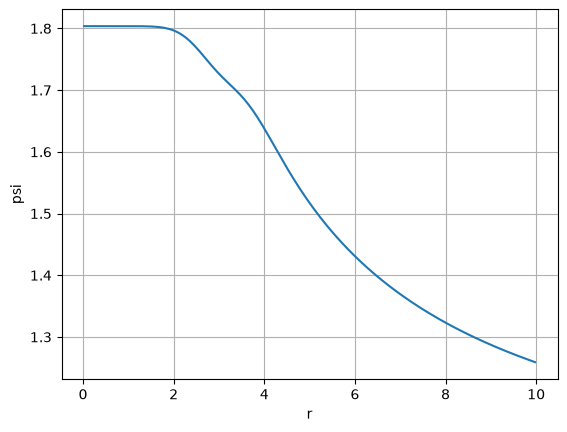

In [ ]:
psi = solve_psi(r_aux, dr, A0, r0, sigma)

print("psi shape:", psi.shape)

plt.plot(r_aux, psi)
plt.xlabel("r")
plt.ylabel("psi")
plt.grid()
plt.show()

In [10]:
dpsi_center_dA = jax.grad(
    lambda amplitude: solve_psi(amplitude)[0]
)(A0)

print("psi at centre:", solve_psi(A0)[0])
print("change in central psi per change in amplitude:", dpsi_center_dA)

psi at centre: 1.803682558144565
change in central psi per change in amplitude: 13.636898784546249


psi shape: (201,)
sensitivity shape: (201,)


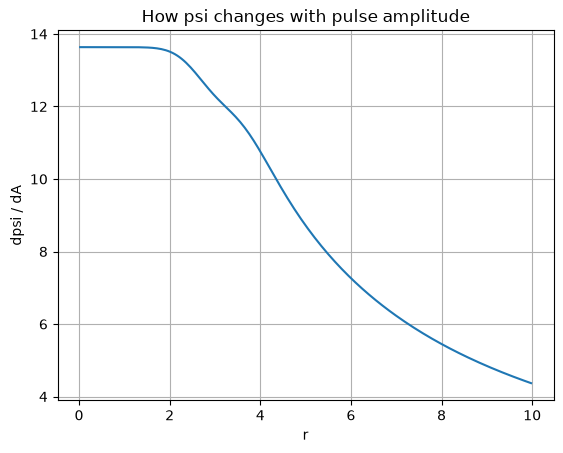

In [ ]:
psi = solve_psi(A0)

# Sensitivity of every psi value to the amplitude
dpsi_dA = jax.jacrev(
    lambda amplitude: solve_psi(r_aux, dr, amplitude, r0, sigma)
)(A0)

print("psi shape:", psi.shape)
print("sensitivity shape:", dpsi_dA.shape)

plt.plot(r_aux, dpsi_dA)
plt.xlabel("r")
plt.ylabel("dpsi / dA")
plt.title("How psi changes with pulse amplitude")
plt.grid()
plt.show()

Largest difference: 1.2306415619889322e-07


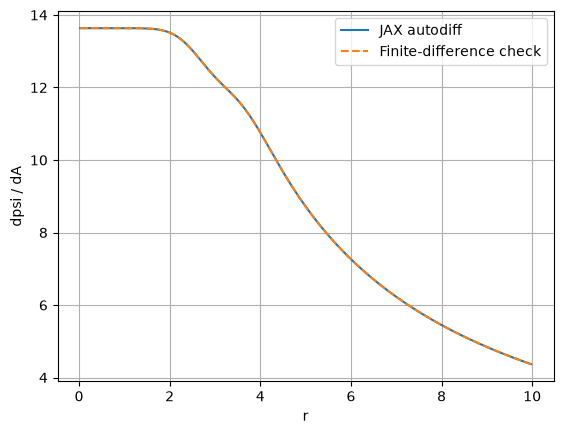

In [12]:
epsilon = 1e-5

# Change the amplitude slightly in both directions
psi_plus = solve_psi(A0 + epsilon)
psi_minus = solve_psi(A0 - epsilon)

# Estimate dpsi/dA using the centred-difference formula
dpsi_dA_finite_difference = (psi_plus - psi_minus) / (2 * epsilon)

# Compare that estimate with JAX's derivative
difference = jnp.max(
    jnp.abs(dpsi_dA - dpsi_dA_finite_difference)
)

print("Largest difference:", difference)

plt.plot(r_aux, dpsi_dA, label="JAX autodiff")
plt.plot(
    r_aux,
    dpsi_dA_finite_difference,
    "--",
    label="Finite-difference check",
)
plt.xlabel("r")
plt.ylabel("dpsi / dA")
plt.legend()
plt.grid()
plt.show()

In [13]:
print("JAX x64 enabled:", jax.config.read("jax_enable_x64"))
print("Shapes:", dpsi_dA.shape, dpsi_dA_finite_difference.shape)
print("Largest JAX sensitivity:", jnp.max(jnp.abs(dpsi_dA)))
print("Largest finite-difference sensitivity:",
      jnp.max(jnp.abs(dpsi_dA_finite_difference)))
print("Largest difference:", jnp.max(jnp.abs(
    dpsi_dA - dpsi_dA_finite_difference
)))

for i in [0, len(r_aux) // 2, len(r_aux) - 1]:
    print(
        i,
        "JAX =", dpsi_dA[i],
        "finite difference =", dpsi_dA_finite_difference[i],
    )

JAX x64 enabled: True
Shapes: (201,) (201,)
Largest JAX sensitivity: 13.636898784546249
Largest finite-difference sensitivity: 13.636898907198878
Largest difference: 1.2306415619889322e-07
0 JAX = 13.636898784546249 finite difference = 13.636898907198878
100 JAX = 8.718513310724498 finite difference = 8.718513393835002
200 JAX = 4.3703157415853235 finite difference = 4.3703157880936585


In [15]:
epsilon = 1e-4

dpsi_dA = jax.jacrev(solve_psi)(A0)

dpsi_dA_finite_difference = (
    solve_psi(A0 + epsilon) - solve_psi(A0 - epsilon)
) / (2 * epsilon)

print("JAX x64 enabled:", jax.config.read("jax_enable_x64"))
print("Largest JAX sensitivity:", jnp.max(jnp.abs(dpsi_dA)))
print("Largest finite-difference sensitivity:",
      jnp.max(jnp.abs(dpsi_dA_finite_difference)))
print("Largest difference:", jnp.max(jnp.abs(
    dpsi_dA - dpsi_dA_finite_difference
)))

JAX x64 enabled: True
Largest JAX sensitivity: 13.636898784546249
Largest finite-difference sensitivity: 13.636910055578877
Largest difference: 1.1271037950066898e-05


# IMPLEMENTATION USING ENGRENAGE

In [17]:
import sys
sys.path.append("../source")

## Create grid

In [31]:
from core.spacing import LinearSpacing, SpacingExtent
from core.grid import Grid
from core.statevector import StateVector
from matter.scalarmatter import ScalarMatter

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=201,
    r_max=10.0,
    extent=SpacingExtent.HALF,
)

grid = Grid(spacing, state_vector)

print("Full grid shape:", grid.r.shape)

Full grid shape: (201,)


## Solve psi on the grid

In [32]:
from core.spacing import NUM_GHOSTS

# grid must use LinearSpacing and HALF extent
r_physical = grid.r[NUM_GHOSTS:-NUM_GHOSTS]
dr_physical = grid.derivs.dx

psi_physical = solve_psi(
    r_physical,
    dr_physical,
    A0,
    r0,
    sigma,
)

print("Engrenage physical radii:", r_physical.shape)
print("psi values:", psi_physical.shape)
print("first radii:", r_physical[:3])
print("last radii:", r_physical[-3:])

Engrenage physical radii: (195,)
psi values: (195,)
first radii: [0.02531646 0.07594937 0.12658228]
last radii: [9.74683544 9.79746835 9.84810127]


In [33]:
from bssn.bssnstatevariables import idx_phi, idx_lapse

physical = slice(NUM_GHOSTS, -NUM_GHOSTS) # slice just ignores the ghost points

u_physical = gaussian_pulse(r_physical, A0, r0, sigma) # make the field values

initial_state = jnp.zeros((grid.NUM_VARS, grid.N)) # start the state as 0

initial_state = initial_state.at[idx_phi, physical].set(
    jnp.log(psi_physical)
)
initial_state = initial_state.at[idx_lapse, physical].set(1.0)
initial_state = initial_state.at[matter.idx_u, physical].set(u_physical)
initial_state = initial_state.at[matter.idx_v, physical].set(0.0)

# Fill the inner and outer ghost points using Engrenage's boundary rules.
initial_state = grid.fill_boundaries(initial_state)

initial_state_flat = initial_state.reshape(-1) # flatten the array

print("State shape:", initial_state.shape)
print("Flattened state shape:", initial_state_flat.shape)
print("All values finite:", jnp.all(jnp.isfinite(initial_state)))

State shape: (14, 201)
Flattened state shape: (2814,)
All values finite: True


In [34]:
from backgrounds.sphericalbackground import FlatSphericalBackground
background = FlatSphericalBackground(grid.r)

print("grid radii:", grid.r.shape)
print("background radii:", background.r.shape)
print("background scaling matrix:", background.scaling_matrix.shape)


grid radii: (201,)
background radii: (201,)
background scaling matrix: (201, 3, 3)


In [35]:
from bssn.constraintsdiagnostic import *
from bssn.constraintsdiagnostic import get_constraints_diagnostic

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)

Ham, Mom = get_constraints_diagnostic(
    initial_state_flat,
    jnp.array([0.0]),
    grid,
    background,
    matter,
)

print("Hamiltonian shape:", Ham.shape)
print("Momentum shape:", Mom.shape)
print("Largest physical Hamiltonian constraint:",
      jnp.max(jnp.abs(Ham[0, physical])))
print("Largest physical momentum constraint:",
      jnp.max(jnp.abs(Mom[0, physical, :])))

Hamiltonian shape: (1, 201)
Momentum shape: (1, 201, 3)
Largest physical Hamiltonian constraint: 0.18465021111502347
Largest physical momentum constraint: 0.0


In [37]:
top = jnp.argsort(jnp.abs(Ham[0, physical]))[-5:][::-1]

for k in top:
    i = int(k) + NUM_GHOSTS
    print(
        "grid index:", i,
        "r:", float(grid.r[i]),
        "Hamiltonian:", float(Ham[0, i]),
    )

# Exclude the last two physical points, where the derivative stencil
# reaches the outer ghost cells.
interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

max_local = int(jnp.argmax(jnp.abs(Ham[0, interior])))
max_index = max_local + NUM_GHOSTS

print("Largest interior Hamiltonian constraint:",
      float(jnp.abs(Ham[0, max_index])))
print("At radius:", float(grid.r[max_index]))

grid index: 197 r: 9.848101265822786 Hamiltonian: 0.18465021111502347
grid index: 196 r: 9.79746835443038 Hamiltonian: -0.013176752381307014
grid index: 62 r: 3.0126582278481013 Hamiltonian: -0.0001938248717494576
grid index: 63 r: 3.0632911392405062 Hamiltonian: -0.00019205707586731182
grid index: 61 r: 2.962025316455696 Hamiltonian: -0.0001835545064547676
Largest interior Hamiltonian constraint: 0.0001938248717494576
At radius: 3.0126582278481013


In [38]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr_physical, amplitude, r0, sigma
    )
    u_physical = gaussian_pulse(
        r_physical, amplitude, r0, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(1.0)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [39]:
state_check = make_initial_state(A0)

print("shape:", state_check.shape)
print("largest difference from previous state:",
      float(jnp.max(jnp.abs(state_check - initial_state_flat))))

shape: (2814,)
largest difference from previous state: 0.0


In [51]:
import diffrax as dfx
from core.rhsevolution import get_rhs

r0_index = int(jnp.argmin(jnp.abs(grid.r - r0)))

def central_lapse_after_evolution(amplitude):
    y0 = make_initial_state(amplitude)

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter)
    save_times = jnp.linspace(0.0, 3.0, 101)
    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=3,
        dt0=0.01,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=dfx.SaveAt(ts=save_times),
        max_steps=350,
    )

    state_history = solution.ys.reshape(save_times.size, grid.NUM_VARS, grid.N)
    central_lapse_history = state_history[:, idx_lapse, NUM_GHOSTS]
    return jnp.min(central_lapse_history)

value = central_lapse_after_evolution(A0)
gradient = jax.grad(central_lapse_after_evolution)(A0)

lapse_at_t3 = central_lapse_after_evolution(A0)
print("Innermost physical lapse at t=3:", float(lapse_at_t3))

Innermost physical lapse at t=3: 0.9914337765840537


In [62]:
A = 0.31
min_lapse = central_lapse_after_evolution(A)
print("A =", A)
print("Minimum central lapse =", float(min_lapse))

A = 0.31
Minimum central lapse = 1.0


In [47]:
lapse_gradient_ad = jax.grad(central_lapse_after_evolution)(A0)

h = 1e-4
lapse_gradient_fd = (
    central_lapse_after_evolution(A0 + h)
    - central_lapse_after_evolution(A0 - h)
) / (2 * h)

print("JAX gradient:", float(lapse_gradient_ad))
print("Finite-difference gradient:", float(lapse_gradient_fd))

JAX gradient: 1.0867345070699557
Finite-difference gradient: 1.086755566560571


In [ ]:
h = 1e-4

gradient_fd = (
    central_lapse_after_evolution(A0 + h)
    - central_lapse_after_evolution(A0 - h)
) / (2 * h)

gradient_ad = jax.grad(central_lapse_after_evolution)(A0)

print("JAX gradient:", float(gradient_ad))
print("Finite-difference gradient:", float(gradient_fd))
print("Difference:", float(jnp.abs(gradient_ad - gradient_fd)))

JAX gradient: 0.00018683150331101362
Finite-difference gradient: 0.00018683291191923246
Difference: 1.408608218836458e-09


In [53]:
test_amplitudes = [0.35, 0.4]

for amplitude in test_amplitudes:
    lapse = central_lapse_after_evolution(amplitude)
    print(f"A = {amplitude:.2f}, central lapse = {float(lapse):.6f}")

A = 0.35, central lapse = nan
A = 0.40, central lapse = nan


In [54]:
for amplitude in [0.35, 0.40]:
    y0 = make_initial_state(amplitude)
    state_ok = bool(jnp.all(jnp.isfinite(y0)))

    print(f"A = {amplitude:.2f}")
    print("  initial state is finite:", state_ok)

    if state_ok:
        rhs0 = get_rhs(0.0, y0, grid, background, matter)
        print("  initial RHS is finite:",
              bool(jnp.all(jnp.isfinite(rhs0))))
        print("  largest absolute RHS value:",
              float(jnp.max(jnp.abs(rhs0))))

A = 0.35
  initial state is finite: False
A = 0.40
  initial state is finite: False


In [55]:
for amplitude in [0.35, 0.40]:
    psi = solve_psi(
        r_physical, dr_physical, amplitude, r0, sigma
    )

    print(f"A = {amplitude:.2f}")
    print("  psi is finite:", bool(jnp.all(jnp.isfinite(psi))))
    print("  minimum psi:", float(jnp.min(psi)))
    print("  number of non-positive psi values:",
          int(jnp.sum(psi <= 0)))

A = 0.35
  psi is finite: True
  minimum psi: -4.8957578587987935
  number of non-positive psi values: 195
A = 0.40
  psi is finite: True
  minimum psi: -2.069826708733362
  number of non-positive psi values: 188


In [56]:
for amplitude in [0.30, 0.31, 0.32, 0.33, 0.34, 0.35]:
    psi = solve_psi(
        r_physical, dr_physical, amplitude, r0, sigma
    )

    print(
        f"A = {amplitude:.2f}",
        f"min(psi) = {float(jnp.min(psi)):.6f}",
        f"max(psi) = {float(jnp.max(psi)):.6f}",
        f"all psi positive = {bool(jnp.all(psi > 0))}",
    )

A = 0.30 min(psi) = 5.282821 max(psi) = 14.295279 all psi positive = True
A = 0.31 min(psi) = 20.639308 max(psi) = 62.076624 all psi positive = True
A = 0.32 min(psi) = -26.085236 max(psi) = -7.692939 all psi positive = False
A = 0.33 min(psi) = -10.720331 max(psi) = -2.754220 all psi positive = False
A = 0.34 min(psi) = -6.728441 max(psi) = -1.470468 all psi positive = False
A = 0.35 min(psi) = -4.895758 max(psi) = -0.880593 all psi positive = False


In [57]:
for amplitude in [0.20, 0.30, 0.31]:
    psi = solve_psi(
        r_physical, dr_physical, amplitude, r0, sigma
    )
    print(
        f"A = {amplitude:.2f}",
        f"psi at inner edge = {float(psi[0]):.6f}",
        f"psi at outer edge = {float(psi[-1]):.6f}",
    )

A = 0.20 psi at inner edge = 1.803684 psi at outer edge = 1.262529
A = 0.30 psi at inner edge = 14.295279 psi at outer edge = 5.282821
A = 0.31 psi at inner edge = 62.076624 psi at outer edge = 20.639308


In [58]:
for amplitude in [0.20, 0.30, 0.31]:
    psi = solve_psi(r_physical, dr_physical, amplitude, r0, sigma)

    dpsi_dr_outer = (psi[-1] - psi[-2]) / dr_physical
    robin_value = psi[-1] + r_physical[-1] * dpsi_dr_outer

    print(
        f"A = {amplitude:.2f}",
        f"outer Robin value = {float(robin_value):.6f}",
        f"target = 1",
    )

A = 0.20 outer Robin value = 0.998650 target = 1
A = 0.30 outer Robin value = 0.977980 target = 1
A = 0.31 outer Robin value = 0.899027 target = 1


In [59]:
for amplitude in [0.20, 0.30, 0.31]:
    psi = solve_psi(r_physical, dr_physical, amplitude, r0, sigma)

    dpsi_dr_outer = (
        3 * psi[-1] - 4 * psi[-2] + psi[-3]
    ) / (2 * dr_physical)

    robin_value = psi[-1] + r_physical[-1] * dpsi_dr_outer

    print(
        f"A = {amplitude:.2f}",
        f"outer Robin value = {float(robin_value):.6f}",
        f"target = 1",
    )

A = 0.20 outer Robin value = 1.000021 target = 1
A = 0.30 outer Robin value = 1.000343 target = 1
A = 0.31 outer Robin value = 1.001574 target = 1


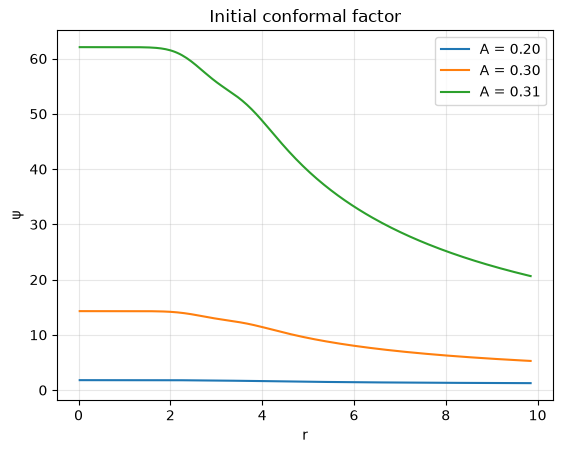

In [60]:
import matplotlib.pyplot as plt

plt.figure()

for amplitude in [0.20, 0.30, 0.31]:
    psi = solve_psi(r_physical, dr_physical, amplitude, r0, sigma)
    plt.plot(r_physical, psi, label=f"A = {amplitude:.2f}")

plt.xlabel("r")
plt.ylabel("ψ")
plt.title("Initial conformal factor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [61]:
amplitude = 0.31
initial_state_flat = make_initial_state(amplitude)

Ham, Mom = get_constraints_diagnostic(
    initial_state_flat,
    jnp.array([0.0]),
    grid,
    background,
    matter,
)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)

# Leave out the last two physical points, where the outer boundary
# can affect the finite-difference constraint.
ham_interior = Ham[0, physical][:-2]
mom_interior = jnp.linalg.norm(Mom[0, physical][:-2], axis=-1)

print("Largest interior Hamiltonian constraint:",
      float(jnp.max(jnp.abs(ham_interior))))
print("Largest interior momentum constraint:",
      float(jnp.max(jnp.abs(mom_interior))))

Largest interior Hamiltonian constraint: 4.5320431923021027e-10
Largest interior momentum constraint: 0.0
